# Zipf の法則を確かめる（順位-頻度プロット）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/05_corpus_statistics/zipf.ipynb)

NLP クックブック 05-04 ／ コーパスの統計と可視化

単語の頻度が順位にほぼ反比例すること（Zipf の法則）を、両対数グラフで確かめたい。

In [1]:
!pip install -q fugashi unidic-lite

In [2]:
import io, re, urllib.request, zipfile
from collections import Counter
from fugashi import Tagger

def aozora(url):
    with urllib.request.urlopen(url) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
    text = z.read(z.namelist()[0]).decode("cp932")
    text = re.split(r"-{50,}", text)[2].split("底本：")[0]
    return re.sub(r"《.+?》|［＃.+?］|｜", "", text).replace("\r\n", "\n").strip()

text = aozora("https://www.aozora.gr.jp/cards/000148/files/789_ruby_5639.zip")
tagger = Tagger()
freq = Counter(w.surface for line in text.split("\n") for w in tagger(line))
print("異なり語数:", len(freq), "延べ語数:", sum(freq.values()))

異なり語数: 13769 延べ語数: 209274


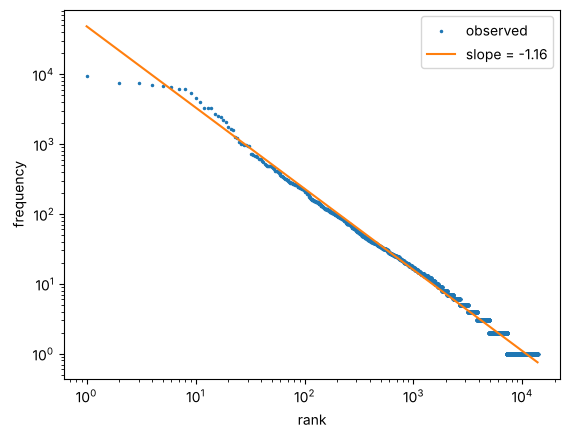

1 回しか出ない語 (hapax): 6539 (47%)


In [3]:
import matplotlib.pyplot as plt
import numpy as np

counts = np.array(sorted(freq.values(), reverse=True))
ranks = np.arange(1, len(counts) + 1)
slope, intercept = np.polyfit(np.log(ranks), np.log(counts), 1)  # 両対数で直線回帰

plt.loglog(ranks, counts, ".", markersize=3, label="observed")
plt.loglog(ranks, np.exp(intercept) * ranks ** slope, label=f"slope = {slope:.2f}")
plt.xlabel("rank"); plt.ylabel("frequency"); plt.legend(); plt.show()

hapax = sum(1 for c in counts if c == 1)
print(f"1 回しか出ない語 (hapax): {hapax} ({hapax / len(counts):.0%})")

- 傾きが -1 付近なら Zipf の法則どおり。語彙の半分前後は 1 回しか出現しない、というのも普遍的な性質。